In [1]:
import os, sys, re, ast
import pandas as pd
import numpy as np
import xarray as xr

In [ ]:
from ooi_data_explorations.common import load_kdata
from ooi_data_explorations.uncabled.process_adcp import correlation_magnitude_qc, error_velocity_qc, horizontal_speed_qc, vertical_velocity_qc, merge_qc, percent_good_qc

In [2]:
from ooinet import M2M
from ooinet.utils import convert_time, ntp_seconds_to_datetime, unix_epoch_time

In [3]:
# Load the local tools
sys.path.append("../ooicgsn_glider_dvl/")

In [4]:
import qc
import profiles
from utils import unix_time

--- 
## Vendor QAQC
First, utilize the TRDI Data QA-QC Model rev12-1 thresholds to derive a first-pass QC flag. We assume that the Explorer DVL 600kHz is comparable to the WH600kHz (Wide-Band) for setting the thresholds.
I think the config settings are: 2.0 meter depth cell size, 0.1 ping interval time, 10 pings per ensemble

| Parameter | Good | Suspect | Bad |
| --------- | ---- | ------- | --- |
| Error Velocity Threshold | <=6.3 cm/s | >6.3 cm/s, <=12.6 cm/s | >=12.6 cm/s |
| Correlation Magnitude | >=115 | <115, >=63 | <63 |
| Percent Good | >=63% | <63%, >=50% | <50% |
| BIT Errors | 0 | >=1 | N/A |

In [ ]:
datasets = M2M.search_datasets(array='CP05MOAS', node='GL388')
datasets

In [ ]:
refdes = 'CP05MOAS-GL388-01-ADCPAM000'
eng_refdes = 'CP05MOAS-GL388-00-ENG000000'

#### Download some example data

In [ ]:
site, node, sensor = refdes.split("-", 2)
method = 'recovered_host'

# Load the velocity data
stream = 'adcp_velocity_earth'
data = load_kdata(site, node, sensor, method, stream, tag=f'deployment0008*{refdes}*.nc')

# Load the engineering data
stream = 'adcp_engineering'
engineering = load_kdata(site, node, sensor, method, stream, tag=f'deployment0008*{refdes}*.nc')

# Load the config data
stream = 'adcp_config'
config = load_kdata(site, node, sensor, method, stream, tag=f'deployment0008*{refdes}*.nc')

# Load the bottom track data
stream = 'adcp_bottom_track_earth'
bottom_track = load_kdata(site, node, sensor, method, stream, tag=f'deployment0008*{refdes}*.nc')

In [ ]:
M2M.get_datastreams(eng_refdes)

In [ ]:
# Load the config data
stream = 'glider_eng_recovered'
glider_eng = load_kdata(site, node, '00-ENG000000', method, stream, tag=f'deployment0008*{eng_refdes}*.nc')
glider_eng

In [ ]:
with open("../data/save_url.csv", 'w') as f:
    f

In [ ]:
from dask.diagnostics import ProgressBar

In [ ]:
 dodsC = M2M.URLS["dodsC"]
files = [re.sub("catalog.html\?dataset=", dodsC, file) for file in catalog[-1]]
print(f"----- Load {method}-{stream} data -----")
with ProgressBar():
    eng_data = xr.open_dataset(files)

### Water velocity profile QA/QC
Do this using the vendor values, but ignore the horizontal and vertical velocity tests since the glider is itself moving through the water

In [ ]:
percent_good = qc.percent_good_qc(data, 63, 50)
corr_mag = qc.correlation_magnitude_qc(data, 115, 63)
error_vel = qc.error_velocity_qc(data, 12.6, 6.3)

In [ ]:
qc_flag = qc.merge_qc([percent_good, corr_mag, error_vel])
qc_flag

In [ ]:
# Now add the qc_flags to the 
data['vendor_qc_flag'] = (['time','bin'], qc_flag)
data['vendor_qc_flag']

---
### Cartopy Practice

Need to practice using cartopy in order to figure out how to do mapping of the glider lines

In [5]:
bathy = xr.open_dataset("../data/external/gebco_2024_n42.0_s38.0_w-74.0_e-67.0.nc")
bathy

<xarray.Dataset> Size: 3MB
Dimensions:    (lat: 960, lon: 1680)
Coordinates:
  * lat        (lat) float64 8kB 38.0 38.01 38.01 38.01 ... 41.99 41.99 42.0
  * lon        (lon) float64 13kB -74.0 -73.99 -73.99 ... -67.01 -67.01 -67.0
Data variables:
    elevation  (lat, lon) int16 3MB ...
Attributes: (12/36)
    title:                           The GEBCO_2024 Grid - a continuous terra...
    summary:                         The GEBCO_2024 Grid is a continuous, glo...
    keywords:                        BATHYMETRY/SEAFLOOR TOPOGRAPHY, DIGITAL ...
    Conventions:                     CF-1.6, ACDD-1.3
    id:                              DOI: 10.5285/1c44ce99-0a0d-5f4f-e063-708...
    naming_authority:                https://dx.doi.org
    ...                              ...
    geospatial_vertical_units:       meters
    geospatial_vertical_resolution:  1.0
    geospatial_vertical_positive:    up
    identifier_product_doi:          DOI: 10.5285/1c44ce99-0a0d-5f4f-e063-708...
    references:                      DOI: 10.5285/1c44ce99-0a0d-5f4f-e063-708...
    node_offset:                     1.0

In [6]:
# For MAB, need (37, -76), (37, -74), (35, -76), (35, 74)

In [6]:
tid = xr.open_dataset("../data/external/GEBCO_2024_TID.nc")

# Filter out for only the longitudes/latitudes that we want
cond = (tid.lon >= -74) & (tid.lon <= -67) & (tid.lat >= 38) & (tid.lat <= 42)
tid = tid.where(cond, drop=True)

In [7]:
land_sea_mask = tid.tid == 0
masked_elv = np.ma.masked_where(land_sea_mask, bathy['elevation'])
lon_grid, lat_grid = np.meshgrid(bathy['elevation'].lon, bathy['elevation'].lat)

#### Next steps:

1. Figure out how to identify and separate dives
2. Identify when and where the glider is at the surface for the adcp dataset

In [8]:
# For this example we will be using CP05MOAS-GL379 D00008, which was deployed at the Pioneer NES array from 2019-09-27 to 2019-11-19.
refdes = 'CP05MOAS-GL379-01-ADCPAM000'
eng_refdes = 'CP05MOAS-GL379-00-ENG000000'
deployment = 8

In [9]:
dep_str = f"{deployment:04d}"  # always 4 digits, e.g., '0008'
glider_name = '-'.join(refdes.split('-')[:2]) # shorten ref des to get glider name

In [10]:
glider = xr.open_dataset(f"../data/processed/{glider_name}.deployment{dep_str}.merged.nc").load()

In [11]:
data = glider.copy()

In [25]:
glider_box = [[-70.375000,-71.166664,-71.166664,-70.375000],[40.083332,40.083332,39.833332,39.833332]]
glider_box[0]


[-70.375, -71.166664, -71.166664, -70.375]

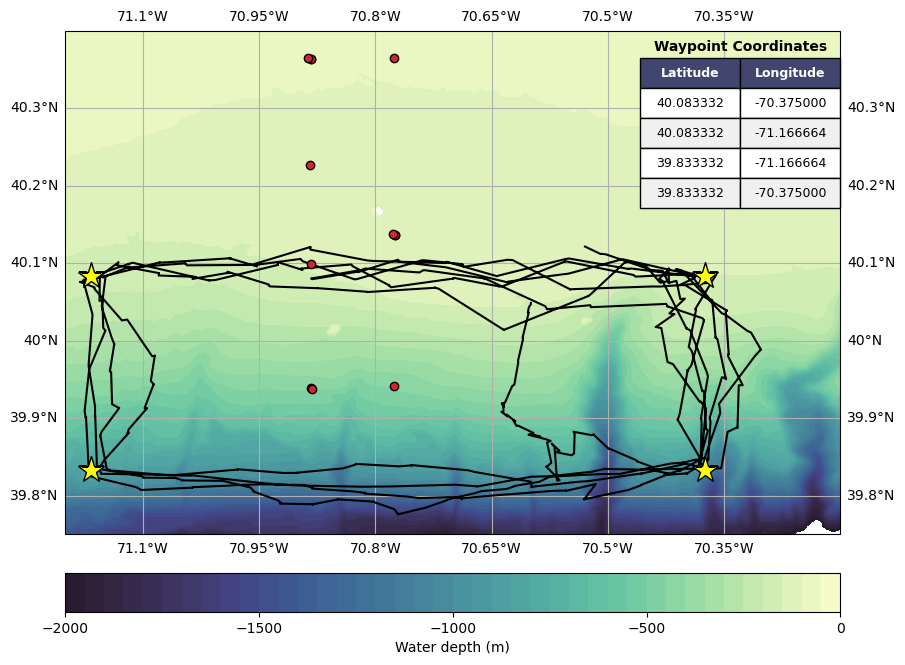

In [59]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
import cmocean

fig=plt.figure(figsize=(10,10))
ax=fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-71.2, -70.2, 39.4, 40.4], crs=ccrs.PlateCarree())
ax.coastlines(resolution="10m")
ax.add_feature(cfeature.BORDERS)
ax.gridlines(draw_labels=True)
#ax.add_geometries(shpreader.Reader(states_shp).geometries(), ccrs.PlateCarree(),
#                  facecolor='lightgray', alpha=0.4)

img=ax.contourf(lon_grid, lat_grid, masked_elv, levels=np.arange(-2000, 25, 50), 
                transform=ccrs.PlateCarree(), corner_mask=True, cmap=cmocean.cm.deep_r)

plt.colorbar(img, extend='min', orientation='horizontal', label='Water depth (m)', ticks=[-2000,-1500, -1000, -500, 0], pad=0.05)

# Now plot the glider track on top of the map bottom
ax.plot(data['lon'], data['lat'], color='black')

# Now add in mooring locations
ax.plot(mooring_locations['lon'], mooring_locations['lat'], marker="o", linestyle="", markeredgecolor="black", color="tab:red")
ax.plot(glider_box[0], glider_box[1], marker='*', linestyle="", markersize=20, markeredgecolor="black", color="yellow")
# #ax.plot(df['lon'][mask], df['lat'][mask], marker='.', linestyle="", color="tab:cyan")
# ax.plot(waypoints['c_wpt_lon'], waypoints['c_wpt_lat'], marker='*', linestyle="", color="yellow")

dx = 0.01   # degrees longitude
dy = 0.01   # degrees latitude

ax.set_ylim(ymin=39.75)

# Create table data
table_data = [
    ['40.083332', '-70.375000'],
    ['40.083332', '-71.166664'],
    ['39.833332', '-71.166664'],
    ['39.833332', '-70.375000']
]

# Create a separate axis for the table (no projection)
table_ax = fig.add_axes([0.70, 0.59, 0.20, 0.15])  # [left, bottom, width, height]
table_ax.axis('off')  # Hide the axis

# Add table to the separate axis
table = table_ax.table(cellText=table_data,
                       colLabels=['Latitude', 'Longitude'],
                       cellLoc='center',
                       loc='center',
                       bbox=[0, 0, 1, 1])

# Customize table appearance
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)  # Scale cell height

# Style the header row
for i in range(2):  # 2 columns
    table[(0, i)].set_facecolor('#40466e')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Style data rows with alternating colors
for i in range(1, 5):  # 4 data rows
    for j in range(2):  # 2 columns
        if i % 2 == 0:
            table[(i, j)].set_facecolor('#f0f0f0')
        else:
            table[(i, j)].set_facecolor('white')

# Optionally add a white background box behind the table
table_ax.patch.set_facecolor('white')
table_ax.patch.set_alpha(0.8)

table_ax.text(0.5, 1.05, 'Waypoint Coordinates', transform=table_ax.transAxes,
              fontsize=10, fontweight='bold', ha='center')

plt.show()



In [60]:
fig.savefig("../results/figures/glider_track_with_bathymetry.png", facecolor="white", transparent=False, bbox_inches="tight")

In [15]:
mooring_locations = pd.read_csv("../data/external/mooring_locations.csv")
mooring_locations

,mooring,lat,lon,depth
0,CP01CNPM,40.136172,-70.774114,133.000000
1,CP01CNSM,40.136497,-70.774589,134.031250
2,CP01CNSP,40.137813,-70.777408,133.250000
3,CP02PMCI,40.226715,-70.884176,126.875000
4,CP02PMCO,40.098392,-70.883301,147.411765
5,CP02PMUI,40.364950,-70.775333,94.411765
6,CP02PMUO,39.941455,-70.775943,448.842105
7,CP03ISPM,40.363231,-70.882505,92.000000
8,CP03ISSM,40.364041,-70.883005,93.530648
9,CP03ISSP,40.365248,-70.886730,94.500000


In [ ]:
np.arange(-2000, -2000/4

In [ ]:
if max_depth >= -1000:
    elv_max = np.floor(max_depth/100)*100
    ticks = np.arange(elv_max, 100, 100)
elif (max_depth < -1000) & (max_depth >= -2000):
    # Need to check if it is even or odd
    max_depth = max_depth/100
    

In [ ]:
zip([1600], )

In [ ]:
a = [1500, 1200, 900, 600, 300]
a.insert(0, 1600)

In [ ]:
ints = 4

In [ ]:
max_depth = -1574
elv_max = np.floor(max_depth/100)
elv_max

In [ ]:
elv_max / 4

In [ ]:
-15 // 4

In [ ]:
M2M.URLS

In [ ]:
M2M.get_api(M2M.URLS['vocab']+'/CP14NEPM/SBS01/00-STCENG000')

In [ ]:
M2M.get_deployments('CP10CNSM-MFC31-00-CPMENG000')

In [ ]:
github_url = "https://raw.githubusercontent.com/oceanobservatories/asset-management/refs/heads/master/deployment"

mab_locations = {
    'mooring':[],
    'lat': [],
    'lon': [],
    'depth': []
}

for mooring in M2M.get_api(M2M.URLS['vocab']):
    if mooring.startswith('GI') and 'MOAS' not in mooring:
        # Get the data
        df = pd.read_csv(f'{github_url}/{mooring}_Deploy.csv')
        lat = df['lat'].mean()
        lon = df['lon'].mean()
        depth = df['water_depth'].mean()
        # Save the data
        mab_locations['mooring'].append(mooring)
        mab_locations['lat'].append(lat)
        mab_locations['lon'].append(lon)
        mab_locations['depth'].append(depth)

mab_locations = pd.DataFrame(mab_locations)
mab_locations
        
        
        

In [ ]:
mab_locations.to_csv("../data/external/irminger_mooring_locations.csv", index=False)

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/oceanobservatories/asset-management/refs/heads/master/deployment/CP10CNSM_Deploy.csv")
df[['lat','lon','water_depth']].mean()

In [ ]:
engineering

#### Figure out surfacing info

In [ ]:
from ooinet.M2M import SESSION
from bs4 import BeautifulSoup

# Parse out the dataset_id from the thredds url
thredds_url = 'https://downloads.oceanobservatories.org/async_results/areed@whoi.edu/20250325T203718572Z-CP05MOAS-GL388-00-ENG000000-recovered_host-glider_eng_recovered/'
page = SESSION.get(thredds_url).text
soup = BeautifulSoup(page, "html.parser")
pattern = re.compile('.*\\.csv$')
catalog = sorted([node.get('href') for node in soup.find_all('a', text=pattern)])
catalog

In [ ]:
df = pd.DataFrame()
for file in catalog:
    new_df = pd.read_csv(thredds_url + file)
    df = pd.concat([df, new_df], ignore_index=True)

In [ ]:
df.head()

In [ ]:
from ooinet.utils import ntp_seconds_to_datetime

df['time'] = df['time'].apply(lambda x: ntp_seconds_to_datetime(x))

In [ ]:
df = df.set_index(keys='time')
df.head()

In [ ]:
# Save the dataset
df.to_csv("../data/deployment0008_CP05MOAS-GL388-00-ENG000000-recovered_host-glider_eng_recovered.csv")

In [ ]:
waypoints = df[['c_wpt_lat','c_wpt_lon']].dropna()
waypoints

In [ ]:
from erddapy import ERDDAP

In [ ]:
e = ERDDAP(server='https://gliders.ioos.us/erddap')

url = e.get_search_url(search_for="ooi", response="csv")

df = pd.read_csv(url)

In [ ]:
[x for x in df['Dataset ID'] if 'cp_388' in x]

In [ ]:
e.dataset_id = 'cp_388-20190618T2258-delayed'
e.protocol = 'tabledap'
e.constraints = None
data_url = e.get_download_url(response='opendap')

In [ ]:
info_url = e.get_info_url(response="csv")

info = pd.read_csv(info_url)
info.head()

In [ ]:
ds = e.to_xarray()
ds['time'] = ds['precise_time']
ds = ds.drop_vars(names='precise_time')
ds = ds.swap_dims({'obs':'time'})
ds.load()

In [ ]:
ds.to_netcdf("../data/ioos_gdac_CP05MOAS-GL388_deployment0008.nc", format='netcdf4', engine='h5netcdf')

In [ ]:
gdac = xr.load_dataset("../data/ioos_gdac_CP05MOAS-GL388_deployment0008.nc")
gdac

Merge the GDAC and DVL datasets

In [ ]:
from merge import merge_datasets, split_data, sensor_variables

In [ ]:
def merge_datasets(dvl: xr.Dataset, gdac: xr.Dataset) -> xr.Dataset:
    """Merge the DVL and GDAC glider datasets
    
    Select and interpolate the science and glider sensor
    data from the OOI GDAC glider dataset to the associated
    OOI DVL glider dataset. First, the science and glider 
    sensor data are separately split into separate datasets.
    Then they are interpolated to the DVL timebase. Finally
    they are merged into the DVL datasets.
    
    Parameters
    ----------
    dvl: xarray.Dataset
        The OOI glider DVL dataset downloaded from OOI
    gdac: xarray.Dataset
        The associated OOI glider data downloaded from the
        IOOS GDAC server
        
    Returns
    -------
    dvl: xarray.Dataset
        The glider DVL data with the science and glider
        data from the GDAC dataset interpolated to the DVL
        timebase and merged
    """
    # First, get the sensor variables
    sensor_vars = sensor_variables(gdac)

    # Next, get the data for each variable set, interpret
    # it to the dvl time base, and merge into the dvl dataset
    for sensor in sensor_vars:
        if sensor == 'profile':
            continue
        else:
            sensor_data = split_data(gdac, sensor_vars[sensor])
            # Now rename the variables to have the source sensor
            # in the name
            for v in sensor_data.variables:
                sensor_data = sensor_data.rename_vars({v: '_'.join((sensor, v))})
            
            # Now interpolate the sensor data to the dvl time base
            interp_sensor = sensor_data.interp_like(dvl['time'], method='linear', kwargs={'fill_value':'extrapolate'})
    
            # Check if depth is a coordinate, and if so, drop it
            if 'depth' in interp_sensor.coords:
                interp_sensor = interp_sensor.drop_vars('depth')
    
            # Merge the interpolated sensor data with the dvl data
            dvl = xr.merge([dvl, interp_sensor])

    return dvl

In [ ]:
dvl = data.copy()

In [ ]:
 # First, get the sensor variables
sensor_vars = sensor_variables(gdac)

# Next, get the data for each variable set, interpret
# it to the dvl time base, and merge into the dvl dataset
for sensor in sensor_vars:
    if sensor == 'profile':
        continue
    else:
        sensor_data = split_data(gdac, sensor_vars[sensor])
        # Now rename the variables to have the source sensor
        # in the name
        for v in sensor_data.variables:
            if v == 'time':
                pass
            else:
                sensor_data = sensor_data.rename_vars({v: '_'.join((sensor, v))})
        
        # Now interpolate the sensor data to the dvl time base
        interp_sensor = sensor_data.interp_like(dvl['time'], method='linear', kwargs={'fill_value':'extrapolate'})

        # Check if depth is a coordinate, and if so, drop it
        if 'depth' in interp_sensor.coords:
            interp_sensor = interp_sensor.drop_vars('depth')

        # Merge the interpolated sensor data with the dvl data
        dvl = xr.merge([dvl, interp_sensor])

In [ ]:
for v in sensor_data.variables:
    if v in sensor_data.coords:
        print(v)

In [ ]:
gdac

In [ ]:
# Need to merge the data from the IOOS gliderDAC to the ADCP timebase
# First, grab the ctd data
ctd_vars = []
oxy_vars = []
flbbcd_vars = []
par_vars = []
glider_vars = []
profile_vars = []
for var in ds.variables:
    if ds[var].dims[0] == 'profile':
        profile_vars.append(var)
    elif 'instrument' in ds[var].attrs:
        if var == 'platform_meta':
            continue
        elif 'ctd' in ds[var].attrs['instrument']:
            ctd_vars.append(var)
        elif 'oxy' in ds[var].attrs['instrument']:
            oxy_vars.append(var)
        elif 'par' in ds[var].attrs['instrument']:
            par_vars.append(var)
        elif 'flbbcd' in ds[var].attrs['instrument']:
            flbbcd_vars.append(var)
        else:
            pass
    elif 'source_sensor' in ds[var].attrs and 'instrument' not in ds[var].attrs:
        glider_vars.append(var)
    else:
        pass

In [ ]:
#

In [ ]:
ctd_vars

In [ ]:
# Now separate the different datasets
ctd_data = ds[ctd_vars]
ctd_data = ctd_data.dropna(dim='time')
interp_ctd = ctd_data.interp_like(data['time'], method='linear', kwargs={'fill_value':'extrapolate'})

In [ ]:
interp_ctd

In [ ]:
oxy_data = ds[oxy_vars]
oxy_data = oxy_data.dropna(dim='time')
interp_oxy = oxy_data.interp_like(data['time'], method='linear', kwargs={'fill_value':'extrapolate'})
interp_oxy

In [ ]:
par_data = ds[par_vars]
par_data = par_data.dropna(dim='time')
interp_par = par_data.interp_like(data['time'], method='linear', kwargs={'fill_value':'extrapolate'})
interp_par

In [ ]:
flbbcd_data = ds[flbbcd_vars]
flbbcd_data = flbbcd_data.dropna(dim='time')
interp_flbbcd = flbbcd_data.interp_like(data['time'], method='linear', kwargs={'fill_value':'extrapolate'})
interp_flbbcd

In [ ]:
# https://github.com/WHOIGit/ooicgsn-profile-data-formatter/blob/main/legacy/gliderdac/ooidac/profiles.py
from scipy import signal
import numpy.typing as npt

def boxcar_smooth_filter(dataset, window_size):
    window = signal.windows.boxcar(window_size)
    return signal.convolve(dataset, window, 'same') / window_size

In [ ]:
def unix_time(dt, unit='s'):
    """Convert numpy datetime64 object to unix time"""
    return (dt - np.datetime64('1970-01-01T00:00:00')) / np.timedelta64(1, unit)
    

def identify_profiles(ds: xr.Dataset) -> np.ndarray:
    """Identify the start of each profile dive.
    
    The glider ADCP is only on during the dive portion
    of each glider profile. We identify where the change
    in depth between each measurement (~4 seconds) is greater
    than 2 meters, indicating the start of a new dive.
    
    Parameters
    ----------
    ds: xarray.Dataset
        A dataset of the glider ADCP data with the parameter
        'depth_from_pressure'

    Returns
    -------
    inflection_idx: numpy.array[int]
        The indices indicating the start of a new profile dive
    """
    # Take the absolute different in pressure
    dz_dt = np.abs(ds['depth_from_pressure'].diff(dim='time'))

    # Get the time
    time_ = unix_time(ds['time'].values)
    
    # Identify where the difference is greater than 2 meters
    # and get the associated times with those inflection points
    idx = np.flatnonzero(dz_dt > 2)
    inflection_times = time_[idx]
    inflection_times = np.insert(
        inflection_times,
        [0, len(inflection_times)],
        [time_[0], time_[-1]])
    
    # Use the time range to get the indices for each profile
    inflection_idx = []
    for idx in range(len(inflection_times)-1):
        pstart = inflection_times[idx]
        pend = inflection_times[idx+1]
        profile_idx = np.flatnonzero(
            np.logical_and(
                time_ > pstart,
                time_ <= pend))
        if len(profile_idx) == 0:
            continue
        inflection_idx.append(profile_idx)

    return inflection_idx

def get_profile_ids(ds: xr.Dataset) -> np.ndarray[int]:
    """Create profile ids for the glider ADCP dataset
    
     Parameters
    ----------
    ds: xarray.Dataset
        A dataset of the glider ADCP data with the parameter
        'depth_from_pressure'

    Returns
    -------
    profiles: numpy.array[int]
        An array the length of the input dataset with the 
        profile id added based on the inflection indices
    """
    
    # First, get the inflection indices
    profile_idx = identify_profiles(ds)
    
    # Next, iterate through the 
    profiles = np.zeros(ds['time'].shape)
    for n, idx in enumerate(profile_idx):
        profiles[idx] = n

    profiles = profiles.astype('int')
    return profiles
    

def add_profiles(ds: xr.Dataset) -> xr.Dataset: 
    """Add a sequential id to each glider profile dive

    The glider ADCP is only on during the dive portion
    of each glider profile. We identify where the change
    in depth between each measurement (~4 seconds) is greater
    than 2 meters, indicating the start of a new dive. Each
    sampling point is then matched with the start and stop times
    of an individual profile, and the profile id is added to
    the dataset.

    Parameters
    ----------
    ds: xarray.Dataset
        A dataset of the glider ADCP data with the parameter
        'depth_from_pressure'

    Returns
    -------
    ds: xarray.Dataset
        The input dataset of the glider ADCP data with each
        time point matched with its profile dive id
        
    """
    # Get the profiles
    profiles = get_profile_ids(ds)

    # Add to the dataset
    ds['profile_id'] = (['time'], profiles)
    ds['profile_id'].attrs = {
        'comment': ('The id of each profile in the dataset '
                    'counting sequentially from the first profile.'),
        'long_name': 'Profile ID',
        'ancillary_variables': 'depth_from_pressure',
    }

    return ds

In [ ]:
data = add_profiles(data)
data

In [ ]:
ctd_data = ds[ctd_vars]
ctd_data = ctd_data.dropna(dim='time')
ctd_data

In [ ]:
ctd_data = ctd_data.interp_like(data['time'], method='linear', kwargs={'fill_value':'extrapolate'})
ctd_data

In [ ]:
ctd_data = ctd_data.drop_vars('depth')
for v in ctd_data.variables:
    if v in ctd_data.coords:
        continue
    else:
        ctd_data = ctd_data.rename({v: '_'.join(('ctd', v))})
ctd_data

In [ ]:
xr.merge([data, ctd_data])

In [ ]:
fig, ax = plt.subplots(figsize=(12,8))

a, = np.where(profiles == 250)
b, = np.where(profiles == 251)
c, = np.where(profiles == 252)

ax.plot(data['time'][a], data['depth_from_pressure'][a], marker='.', linestyle="")
ax.plot(data['time'][b], data['depth_from_pressure'][b], marker='.', linestyle="")
ax.plot(data['time'][c], data['depth_from_pressure'][c], marker='.', linestyle="")
#ax.plot(data['time'][inflection_idx[3]], data['depth_from_pressure'][inflection_idx[3]], marker='.', linestyle="")
#ax.plot(data['time'][inflection_idx[4]], data['depth_from_pressure'][inflection_idx[4]], marker='.', linestyle="")



ax.invert_yaxis()

In [ ]:
# Def the merge tools

def sensor_variables(ds):
    """Match IOOS GDAC dataset variables to science sensor source"""

    # Initialize various lists to keep dataset variables in
    ctd_vars = []
    oxy_vars = []
    flbbcd_vars = []
    par_vars = []
    glider_vars = []
    profile_vars = []
    
    # Iterate through the dataset variables and look for the source
    # sensor attribute and match to appropriate list
    for var in ds.variables:
        if ds[var].dims[0] == 'profile':
            profile_vars.append(var)
        elif 'instrument' in ds[var].attrs:
            if var == 'platform_meta':
                continue
            elif 'ctd' in ds[var].attrs['instrument']:
                ctd_vars.append(var)
            elif 'oxy' in ds[var].attrs['instrument']:
                oxy_vars.append(var)
            elif 'par' in ds[var].attrs['instrument']:
                par_vars.append(var)
            elif 'flbbcd' in ds[var].attrs['instrument']:
                flbbcd_vars.append(var)
            else:
                pass
        elif 'source_sensor' in ds[var].attrs and 'instrument' not in ds[var].attrs:
            glider_vars.append(var)
        else:
            pass

    sensor_vars = {
        'ctd': ctd_vars,
        'oxy': oxy_vars,
        'flbbcd': flbbcd_vars,
        'par': par_vars,
        'glider': glider_vars,
        'profile': profile_vars
    }

    return sensor_vars

def split_data(ds, sensor_vars):
    """Splits off the given science variables"""
    sensor_ds = ds[sensor_vars].dropna(dim='time')
    return sensor_ds


def merge_datasets(dvl, gdac):
    """Merge the DVL and GDAC glider datasets"""
    # First, get the sensor variables
    sensor_vars = sensor_variables(gdac)

    # Next, get the data for each variable set, interpret
    # it to the dvl time base, and merge into the dvl dataset
    for sensor in sensor_vars:
        if sensor == 'profile':
            continue
        else:
            sensor_data = split_data(gdac, sensor_vars[sensor])
            # Now rename the variables to have the source sensor
            # in the name
            for v in sensor_data.variables:
                sensor_data = sensor_data.rename_vars({v: '_'.join((sensor, v))})
            
            # Now interpolate the sensor data to the dvl time base
            interp_sensor = sensor_data.interp_like(dvl['time'], method='linear', kwargs={'fill_value':'extrapolate'})
    
            # Check if depth is a coordinate, and if so, drop it
            if 'depth' in interp_sensor.coords:
                interp_sensor = interp_sensor.drop_vars('depth')
    
            # Merge the interpolated sensor data with the dvl data
            dvl = xr.merge([dvl, interp_sensor])

    return dvl
            


In [ ]:
sensor_variables(

In [ ]:
merged_data = merge_datasets(data, ds)
merged_data

In [ ]:
sensor_vars = sensor_variables(ds)
sensor_vars

In [ ]:
gdac = ds.copy()
dvl = data.copy()

In [ ]:
for sensor in sensor_vars:
    if sensor == 'profile':
        continue
    else:
        sensor_data = split_data(gdac, sensor_vars[sensor])

        # Now interpolate the sensor data to the dvl time base
        interp_sensor = sensor_data.interp_like(dvl['time'], method='linear', kwargs={'fill_value':'extrapolate'})

        # Check if depth is a coordinate, and if so, drop it
        if 'depth' in interp_sensor.coords:
            interp_sensor = interp_sensor.drop_vars('depth')

        for v in interp_sensor.variables :
            if v not in interp_sensor.coords:
                interp_sensor = interp_sensor.rename_vars({v: '_'.join((sensor, v))})
        

        # Merge the interpolated sensor data with the dvl data
        dvl = xr.merge([dvl, interp_sensor])

In [ ]:
dvl

In [ ]:
interp_data

In [ ]:
merged_data = merge_datasets(data, ds)
merged_data

In [ ]:
# Lets plot some data
fig, ax = plt.subplots(figsize=(12,8))

t1 = '2019-08-19T00:00:00'
t2 = '2019-08-19T23:59:59'
ctd_subset = ds.sel(time=slice(t1,t2))
int_subset = interp_ctd.sel(time=slice(t1,t2))
data_subset = data.sel(time=slice(t1,t2))
ax.plot(ctd_subset['time'], ctd_subset['depth'], marker=".", linestyle="", color="tab:red")
ax.plot(int_subset['time'], int_subset['depth'], marker=".", linestyle="", color="tab:blue" )
#ax.plot(data_subset['time'], data_subset['non_zero_depth'], marker=".", linestyle="", color="tab:green")





ax.invert_yaxis()

In [ ]:
interp_ds = ds.interp_like(data['time'], kwargs={'fill_value':'extrapolate'}, method_non_numeric='nearest')

In [ ]:
idx_sal, = np.where(ds['salinity'].isnull())
idx_temp, = np.where(ds['temperature'].isnull())
idx_pres, = np.where(ds['pressure'].isnull())

In [ ]:
np.all(idx_temp == idx_pres)

In [ ]:
data['non_zero_depth'][data['non_zero_depth'].isnull()]

In [ ]:
interp_ds['depth'].dropna(dim='time')

In [ ]:
ds['depth'].interp_like(data['time'], method='linear', kwargs={'fill_value':'extrapolate'})

In [ ]:
fig, (ax, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(12,8), sharex=True)

interp_subset = interp_ds.sel(time=slice('2019-06-19'))
ds_subset = ds.sel(time=slice('2019-06-19'))
subset = data.sel(time=slice('2019-06-19'))

ax.plot(ds_subset['time'], ds_subset['depth'], marker='.', linestyle='', color='tab:red')
ax.invert_yaxis()
ax.grid()

ax2.plot(subset['time'], subset['non_zero_depth'], marker='.', linestyle='', color='tab:blue')
ax2.plot(interp_subset['time'], interp_subset['depth'], marker='.', linestyle='', color='tab:green')
ax2.invert_yaxis()
ax2.grid()

In [ ]:
data['time']

In [ ]:
# Try interpolating the 

In [ ]:
sal = ds['salinity'].dropna(dim='ctd_timestamp')
sal.ctd_timestamp

In [ ]:
ctd_refdes = 'CP05MOAS-GL388-03-CTDGVM000'
M2M.get_datastreams(ctd_refdes)

In [ ]:
# Get the data
ctd_data = load_kdata('CP05MOAS', 'GL388', '03-CTDGVM000', 'recovered_host', 'ctdgv_m_glider_instrument_recovered', tag='deployment0008*CP05MOAS-GL388-03-CTDGVM000*.nc')
ctd_data

In [ ]:
# Now interpolate and add the data to the ADCP dataset
cond = ctd_data['sea_water_electrical_conductivity'].interp_like(data.time)
data['sea_water_electrical_conductivity'] = cond
data['sea_water_electrical_conductivity'].attrs['source'] = ctd_refdes

saln = ctd_data['sea_water_practical_salinity'].interp_like(data.time)
data['sea_water_practical_salinity'] = saln
data['sea_water_practical_salinity'].attrs['source'] = ctd_refdes

temp = ctd_data['sea_water_temperature'].interp_like(data.time)
data['sea_water_temperature'] = temp
data['sea_water_temperature'].attrs['source'] = ctd_refdes

saln = ctd_data['sea_water_practical_salinity'].interp_like(data.time)
data['sea_water_practical_salinity'] = saln
data['sea_water_practical_salinity'].attrs['source'] = ctd_refdes

In [ ]:
data

In [ ]:
# Identify the individual profiles
dP = data['non_zero_depth'].diff(dim='time')
idx, = np.where(np.abs(dP) > 10)
idx

In [ ]:
dP